In [ ]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.09MB/s]

Dataset size: 60000
Number of batches: 468
Image shape: torch.Size([3, 32, 32])


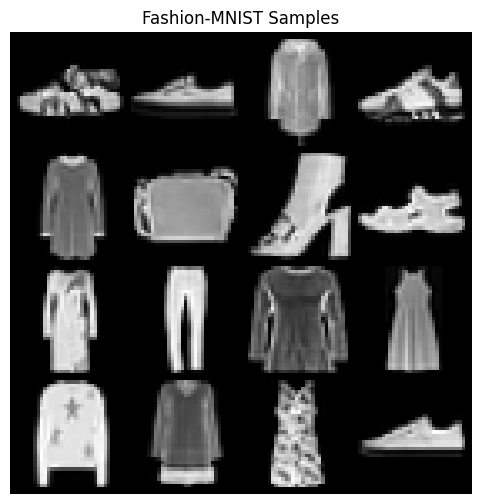

In [ ]:
BATCH_SIZE = 128
IMAGE_SIZE = 32
LATENT_DIM = 128

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    drop_last=True
)

class_names = train_dataset.classes

print("Dataset size:", len(train_dataset))
print("Number of batches:", len(train_loader))
print("Image shape:", train_dataset[0][0].shape)

# Display a sample batch
images, labels = next(iter(train_loader))
sample_grid = utils.make_grid(
    images[:16], nrow=4, normalize=True, value_range=(-1, 1)
)

plt.figure(figsize=(6, 6))
plt.imshow(sample_grid.permute(1, 2, 0))
plt.title("Fashion-MNIST Samples")
plt.axis("off")
plt.show()

In [ ]:
class MappingNetwork(nn.Module):
    def __init__(self, latent_dim=128, num_layers=8):
        super().__init__()

        layers = []
        for i in range(num_layers):
            layers.append(nn.Linear(latent_dim, latent_dim))
            layers.append(nn.LeakyReLU(0.2, inplace=True))

        self.network = nn.Sequential(*layers)

    def forward(self, z):
        # Pixel normalization of latent input
        z = z * torch.rsqrt(
            z.pow(2).mean(dim=1, keepdim=True) + 1e-8
        )
        return self.network(z)

In [ ]:
class AdaIN(nn.Module):
    def __init__(self, channels, latent_dim=128):
        super().__init__()
        self.norm = nn.InstanceNorm2d(channels, affine=False, eps=1e-8)
        self.affine = nn.Linear(latent_dim, channels * 2)

        # Start with scale approximately 1 and bias 0
        nn.init.zeros_(self.affine.weight)
        nn.init.zeros_(self.affine.bias)
        with torch.no_grad():
            self.affine.bias[:channels].fill_(1.0)

    def forward(self, x, w):
        style = self.affine(w)
        scale, bias = style.chunk(2, dim=1)
        scale = scale[:, :, None, None]
        bias = bias[:, :, None, None]
        return self.norm(x) * scale + bias


class StyledConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.adain = AdaIN(out_channels)
        self.activation = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x, w):
        x = self.conv(x)
        x = self.adain(x, w)
        return self.activation(x)


class SynthesisNetwork(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.constant = nn.Parameter(torch.randn(1, 256, 4, 4))
        self.block4 = StyledConvBlock(256, 256)
        self.block8 = StyledConvBlock(256, 128)
        self.block16 = StyledConvBlock(128, 64)
        self.block32 = StyledConvBlock(64, 32)
        self.to_rgb = nn.Conv2d(32, 3, kernel_size=1)

    def forward(self, w1, w2=None, cutoff=2):
        """
        w1: style for early synthesis blocks
        w2: optional style for later blocks
        cutoff: number of early blocks receiving w1
        """
        if w2 is None:
            w2 = w1

        styles = [w1 if i < cutoff else w2 for i in range(4)]
        batch_size = w1.size(0)
        x = self.constant.expand(batch_size, -1, -1, -1)

        x = self.block4(x, styles[0])
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        x = self.block8(x, styles[1])
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        x = self.block16(x, styles[2])
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        x = self.block32(x, styles[3])

        return torch.tanh(self.to_rgb(x))


class Generator(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.mapping = MappingNetwork(latent_dim, num_layers=8)
        self.synthesis = SynthesisNetwork(latent_dim)

    def forward(self, z, z2=None, cutoff=2):
        w1 = self.mapping(z)
        if z2 is None:
            return self.synthesis(w1)
        w2 = self.mapping(z2)
        return self.synthesis(w1, w2, cutoff)

    def generate_from_w(self, w1, w2=None, cutoff=2):
        return self.synthesis(w1, w2, cutoff)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.classifier = nn.Linear(256 * 2 * 2, 1)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(start_dim=1)
        return self.classifier(x)

# Instantiate and check parameter counts
G = Generator(LATENT_DIM).to(device)
D = Discriminator().to(device)

print("Generator parameters:", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

Generator parameters: 1237507
Discriminator parameters: 692065


In [ ]:
LR = 0.0002
BETAS = (0.0, 0.99)

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    G.parameters(), lr=LR, betas=BETAS
)
optimizer_D = optim.Adam(
    D.parameters(), lr=LR, betas=BETAS
)

# Fixed latent vectors for monitoring progress
fixed_z = torch.randn(16, LATENT_DIM, device=device)

def show_generated_images(images, title="Generated Images"):
    images = images.detach().cpu()
    grid = utils.make_grid(
        images, nrow=4, normalize=True, value_range=(-1, 1)
    )

    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1))
    plt.title(title)
    plt.axis("off")
    plt.show()

Epoch [1/10] | G Loss: 1.8801 | D Loss: 1.0734


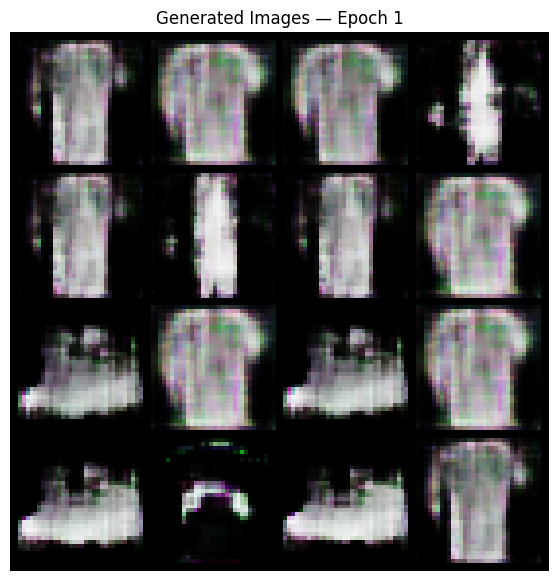

Epoch [2/10] | G Loss: 1.6585 | D Loss: 1.1134


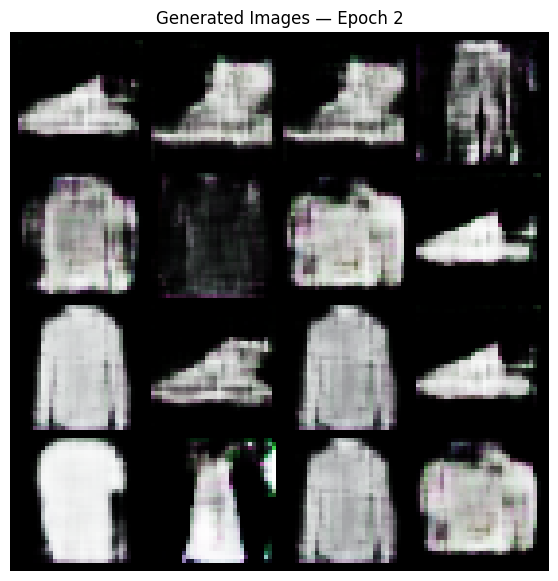

Epoch [3/10] | G Loss: 1.8565 | D Loss: 1.0118


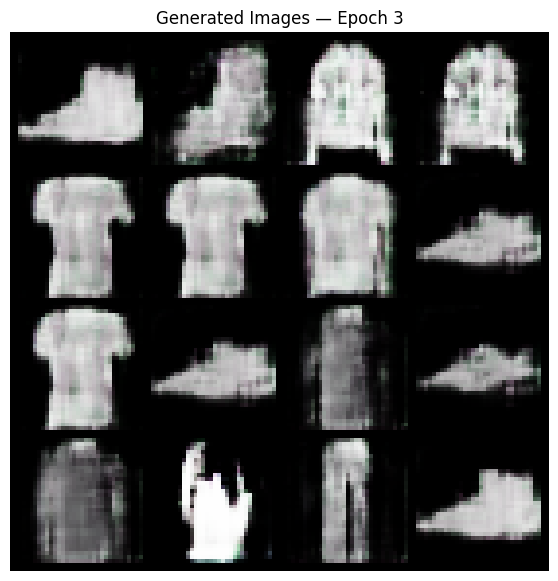

Epoch [4/10] | G Loss: 2.2388 | D Loss: 0.8233


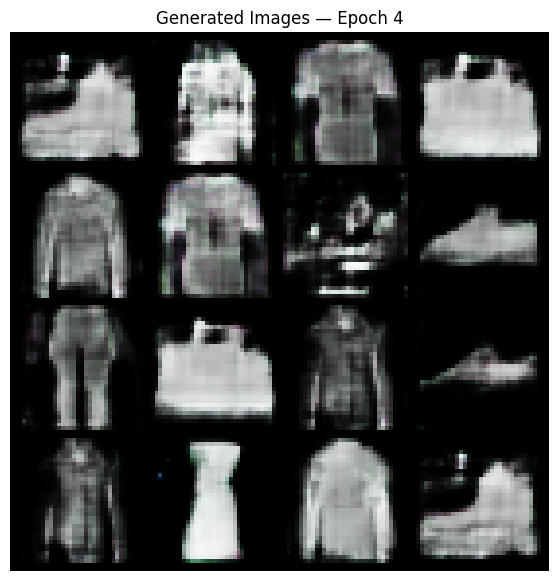

Epoch [5/10] | G Loss: 3.0191 | D Loss: 0.5666


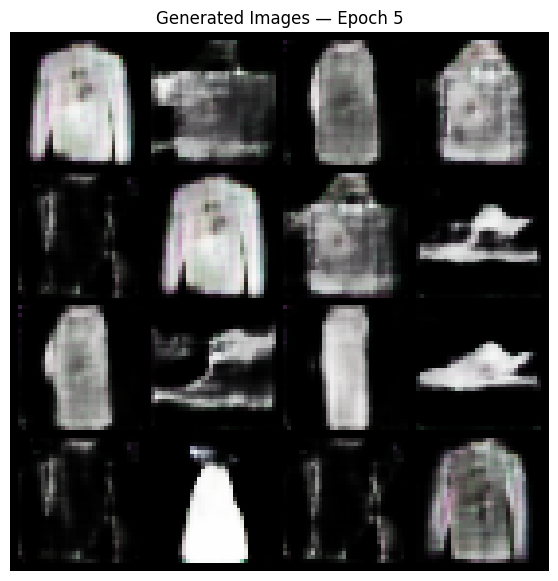

Epoch [6/10] | G Loss: 3.8146 | D Loss: 0.3962


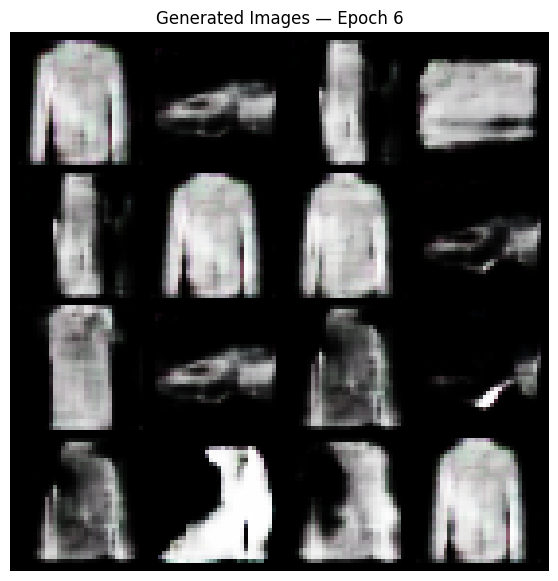

Epoch [7/10] | G Loss: 4.3003 | D Loss: 0.2932


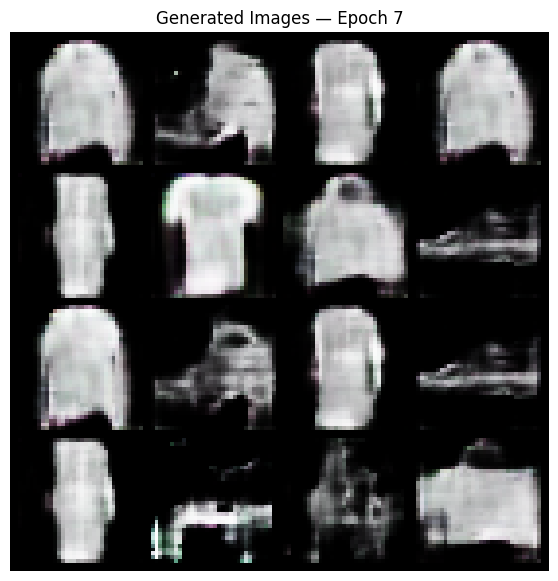

Epoch [8/10] | G Loss: 4.2148 | D Loss: 0.3524


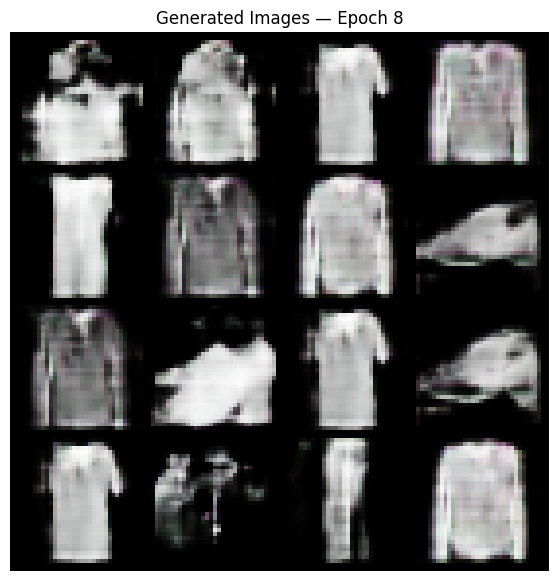

Epoch [9/10] | G Loss: 4.2819 | D Loss: 0.2842


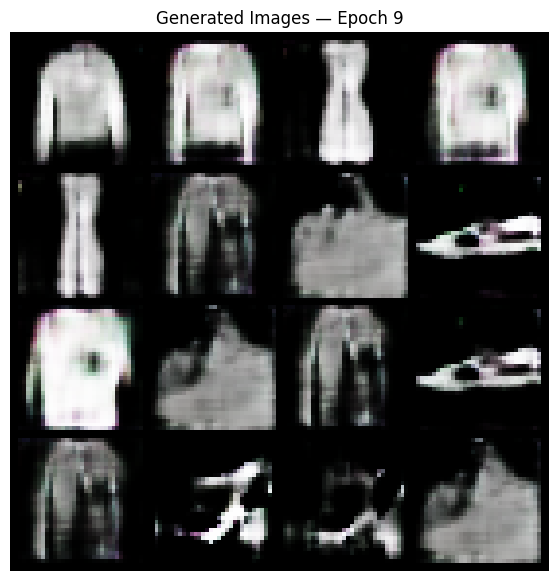

Epoch [10/10] | G Loss: 4.6523 | D Loss: 0.2496


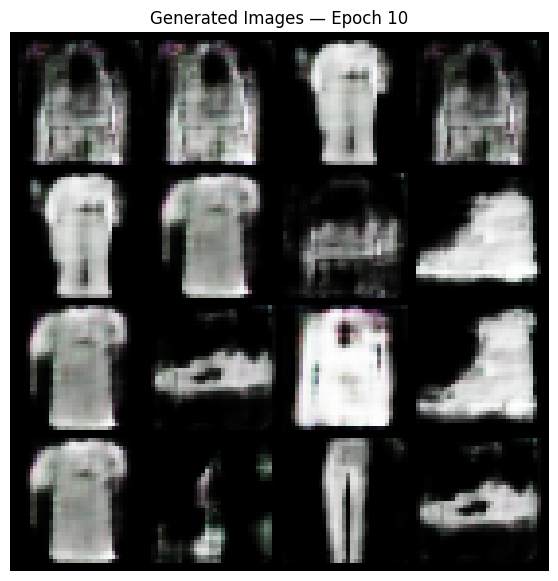

Training completed!


In [12]:
EPOCHS = 10

g_losses = []
d_losses = []

for epoch in range(EPOCHS):
    G.train()
    D.train()

    running_g_loss = 0.0
    running_d_loss = 0.0

    for real_images, _ in train_loader:
        real_images = real_images.to(device, non_blocking=True)
        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, 1, device=device)
        fake_targets = torch.zeros(batch_size, 1, device=device)

        # ----------------------------------
        # 1. Train discriminator
        # ----------------------------------
        optimizer_D.zero_grad(set_to_none=True)

        z = torch.randn(batch_size, LATENT_DIM, device=device)
        with torch.no_grad():
            fake_images = G(z)

        real_logits = D(real_images)
        fake_logits = D(fake_images)

        d_real_loss = criterion(real_logits, real_targets)
        d_fake_loss = criterion(fake_logits, fake_targets)
        d_loss = d_real_loss + d_fake_loss

        d_loss.backward()
        optimizer_D.step()

        # ----------------------------------
        # 2. Train generator
        # ----------------------------------
        optimizer_G.zero_grad(set_to_none=True)

        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = G(z)
        fake_logits = D(fake_images)

        # Generator wants fake images classified as real
        g_loss = criterion(fake_logits, real_targets)

        g_loss.backward()
        optimizer_G.step()

        running_g_loss += g_loss.item()
        running_d_loss += d_loss.item()

    avg_g = running_g_loss / len(train_loader)
    avg_d = running_d_loss / len(train_loader)

    g_losses.append(avg_g)
    d_losses.append(avg_d)

    print(f"Epoch [{epoch + 1}/{EPOCHS}] | G Loss: {avg_g:.4f} | D Loss: {avg_d:.4f}")

    # Preview generated images after each epoch
    G.eval()
    with torch.no_grad():
        samples = G(fixed_z)
        show_generated_images(samples, f"Generated Images — Epoch {epoch + 1}")

print("Training completed!")

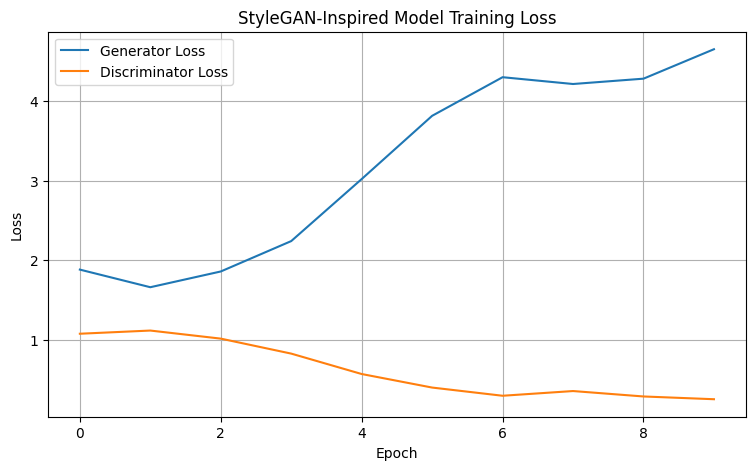

In [13]:

plt.figure(figsize=(9, 5))

plt.plot(g_losses, label="Generator Loss")
plt.plot(d_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("StyleGAN-Inspired Model Training Loss")
plt.legend()
plt.grid(True)
plt.show()


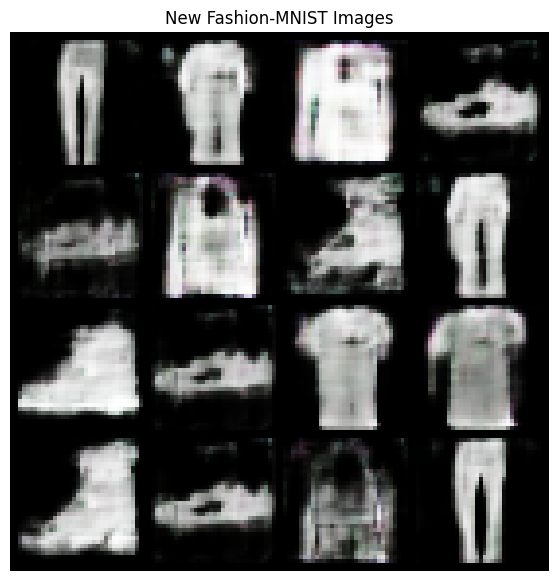

In [16]:
G.eval()

with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, device=device)
    generated_images = G(z)
    show_generated_images(generated_images, "New Fashion-MNIST Images")

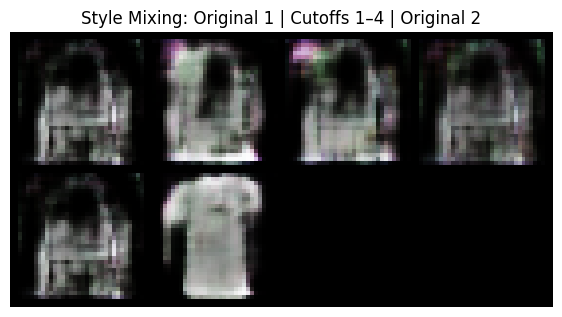

In [17]:
G.eval()

with torch.no_grad():
    z1 = torch.randn(1, LATENT_DIM, device=device)
    z2 = torch.randn(1, LATENT_DIM, device=device)

    w1 = G.mapping(z1)
    w2 = G.mapping(z2)

    # Compare different style-mixing cutoffs
    mixed_images = []

    for cutoff in [1, 2, 3, 4]:
        mixed = G.generate_from_w(w1, w2, cutoff=cutoff)
        mixed_images.append(mixed)

    # Include the original images for comparison
    original1 = G.generate_from_w(w1)
    original2 = G.generate_from_w(w2)

    comparison = torch.cat([original1, *mixed_images, original2], dim=0)

    show_generated_images(
        comparison,
        "Style Mixing: Original 1 | Cutoffs 1–4 | Original 2"
    )

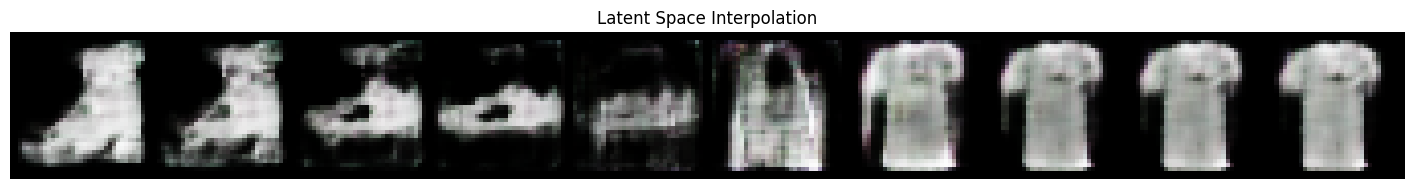

In [18]:
G.eval()

with torch.no_grad():
    z_start = torch.randn(1, LATENT_DIM, device=device)
    z_end = torch.randn(1, LATENT_DIM, device=device)

    steps = 10
    interpolation_images = []

    for t in torch.linspace(0, 1, steps, device=device):
        z_interp = (1 - t) * z_start + t * z_end
        image = G(z_interp)
        interpolation_images.append(image)

    interpolation_images = torch.cat(interpolation_images, dim=0)

    grid = utils.make_grid(
        interpolation_images,
        nrow=steps,
        normalize=True,
        value_range=(-1, 1)
    )

    plt.figure(figsize=(18, 3))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1))
    plt.title("Latent Space Interpolation")
    plt.axis("off")
    plt.show()

In [19]:
torch.save({
    "generator": G.state_dict(),
    "discriminator": D.state_dict(),
    "mapping": G.mapping.state_dict(),
    "epochs": EPOCHS,
    "latent_dim": LATENT_DIM
}, "/content/stylegan_inspired_fashion.pth")

print("Model saved successfully!")
print("/content/stylegan_inspired_fashion.pth")

Model saved successfully!
/content/stylegan_inspired_fashion.pth
